## What does it actually mean to train a machine learning model?

Think about adjusting a shower knob. Too cold? Turn it a little. Too hot? Turn it back. You keep adjusting until it feels right.

**Training a model works the same way, just with numbers.**

In this notebook you'll see:
1. How a model makes a prediction
2. How **loss** tells us how wrong that prediction is
3. How changing one number (the weight) changes the loss
4. How a `for` loop saves us from repeating code, and why a loop is **not** the same as learning

---
## 1. The model: a straight line

$$y = wx + b$$

| Symbol | Name | In shower terms |
|---|---|---|
| `x` | Input | The situation you're in |
| `w` | Weight | **The knob**, how strongly x affects the output |
| `b` | Bias | A fixed shift (kept at 0 for now) |
| `y` | Output | The model's prediction |

**The problem:** we give the model `x = 3`, and we want it to predict `6`.

---
## 2. Step 1: Make a guess

Let's set the knob to `w = 0.5` and see what the model predicts.

In [1]:
x = 3      # input
y = 6      # the correct answer
w = 0.5    # our first guess for the weight
b = 0      # bias, kept at zero

y_pred = w * x + b
print("Prediction:", y_pred)

Prediction: 1.5


The model said **1.5**, but the answer is **6**. How wrong is that, as a single number?

### Loss

$$\text{Loss} = (\text{Prediction} - \text{Actual})^2$$

**Why square it?**
- **It keeps the loss positive.** Being 2 too high and 2 too low are equally wrong, and the errors can't cancel out.
- **Big mistakes cost more.** An error of 1 costs 1, but an error of 4 costs 16.

Think of loss as a "wrongness score". **Lower is better, and 0 means perfect.**

In [2]:
loss = (y_pred - y) ** 2
print("Loss:", loss)

Loss: 20.25


---
## 3. Step 2: Turn the knob

The simplest way to try another weight is to **copy the same code and change only `w`**. Let's do exactly that.

In [3]:
w = 0.6
y_pred = w * x + b
loss = (y_pred - y) ** 2
print("w:", w, "| prediction:", round(y_pred, 2), "| loss:", round(loss, 2))

w: 0.6 | prediction: 1.8 | loss: 17.64


In [4]:
w = 1.0
y_pred = w * x + b
loss = (y_pred - y) ** 2
print("w:", w, "| prediction:", round(y_pred, 2), "| loss:", round(loss, 2))

w: 1.0 | prediction: 3.0 | loss: 9.0


In [5]:
w = 2.0
y_pred = w * x + b
loss = (y_pred - y) ** 2
print("w:", w, "| prediction:", round(y_pred, 2), "| loss:", round(loss, 2))

w: 2.0 | prediction: 6.0 | loss: 0.0


In [6]:
w = 2.5
y_pred = w * x + b
loss = (y_pred - y) ** 2
print("w:", w, "| prediction:", round(y_pred, 2), "| loss:", round(loss, 2))

w: 2.5 | prediction: 7.5 | loss: 2.25


**What we see:**
- The loss **falls** as `w` gets closer to 2.
- At `w = 2.0`, the prediction is exactly 6 and the **loss is 0**.
- At `w = 2.5`, we **overshoot** and the loss rises again.

So we're not looking for the *biggest* weight. We're looking for the weight with the **smallest loss**.

---
## 4. Step 3: Stop repeating yourself

Look at the four cells above. They're **identical except for one number**. Whenever you notice you're copying code and changing just one value, that's a sign to use a **`for` loop**.

### What is a `for` loop?

A `for` loop **repeats the same instructions for every item in a list**.

```python
for w in [0.5, 0.6, 1.0, 2.0, 2.5]:
    prediction = w * 3
    loss = (prediction - 6) ** 2
```

**Reading it line by line:**
- `for w in [...]:` → take each value from the list, **one at a time**, and call it `w`
- The **indented lines** → the instructions that repeat for every value (Python uses the indentation to know what's inside the loop)

**So Python runs it in rounds:**

| Round | `w` | Prediction | Loss |
|---|---|---|---|
| 1 | 0.5 | 1.5 | 20.25 |
| 2 | 0.6 | 1.8 | 17.64 |
| 3 | 1.0 | 3.0 | 9.00 |
| 4 | 2.0 | 6.0 | 0.00 |
| 5 | 2.5 | 7.5 | 2.25 |

...and then the list runs out, so the loop stops.

Think of a teacher marking a stack of answer sheets. **The marking steps never change; only the sheet does.**

In [7]:
x, y, b = 3, 6, 0

for w in [0.5, 0.6, 1.0, 2.0, 2.5]:
    y_pred = w * x + b
    loss = (y_pred - y) ** 2
    print(f"w = {w:<4} -> prediction = {y_pred:<4.1f} loss = {loss:.2f}")

w = 0.5  -> prediction = 1.5  loss = 20.25
w = 0.6  -> prediction = 1.8  loss = 17.64
w = 1.0  -> prediction = 3.0  loss = 9.00
w = 2.0  -> prediction = 6.0  loss = 0.00
w = 2.5  -> prediction = 7.5  loss = 2.25


Five blocks of code became one, and adding a sixth weight is now just one more number in the list.

### ⚠️ A loop is not learning

Notice what the loop does and doesn't do:

| | Loop | Machine learning |
|---|---|---|
| Calculates prediction & loss | ✅ automatically | ✅ automatically |
| Decides **which weight to try next** | ❌ **we** chose every weight | ✅ the model decides, using the loss |

The loop automates the **calculation**. It doesn't **learn**. If we had never written `2.0` in the list, it would never have found the answer.

Real training means the model **picks its next weight by itself**, using the loss as feedback, like your hand adjusting the shower knob.

---
## 5. Sneak peek: the shape of the loss

Instead of five weights, let's compute the loss for *hundreds* of them and plot it.

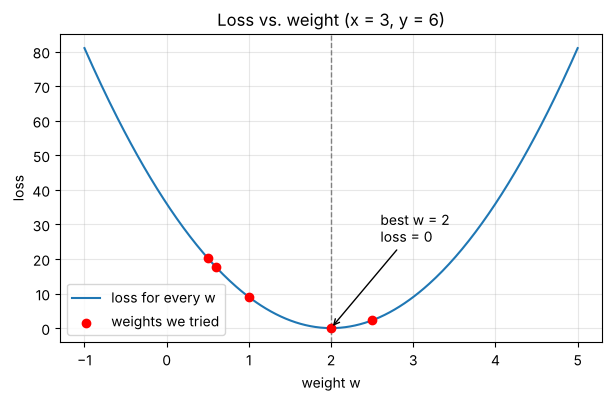

In [8]:
import numpy as np
import matplotlib.pyplot as plt

ws = np.linspace(-1, 5, 300)
losses = (ws * x - y) ** 2

tried = np.array([0.5, 0.6, 1.0, 2.0, 2.5])
tried_losses = (tried * x - y) ** 2

plt.figure(figsize=(7, 4))
plt.plot(ws, losses, label="loss for every w")
plt.scatter(tried, tried_losses, color="red", zorder=3, label="weights we tried")
plt.axvline(2, linestyle="--", color="gray", linewidth=1)
plt.annotate("best w = 2\nloss = 0", xy=(2, 0), xytext=(2.6, 25),
             arrowprops=dict(arrowstyle="->"))
plt.xlabel("weight w")
plt.ylabel("loss")
plt.title("Loss vs. weight (x = 3, y = 6)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A **U-shaped curve** with its lowest point exactly at `w = 2`. Training a model means **finding the bottom of this curve**.

---
## 6. Key takeaways

| Concept | In one line |
|---|---|
| **Model** | A formula that turns an input into a prediction: `w * x + b` |
| **Weight** | The knob the model can turn |
| **Loss** | A wrongness score: lower is better, 0 is perfect |
| **Loop** | Repeats the calculation for weights *we* choose |
| **Training** | The model chooses the next weight itself, guided by the loss |

### Try it yourself
1. Change the problem to `x = 4, y = 10`. Which weight gives zero loss now?
2. Add `3.0` and `1.5` to the loop's list. Where do they land on the curve?
3. Write a loop that tries `w` from 0 to 4 in steps of 0.1 and prints the one with the smallest loss. (Hint: `np.arange(0, 4, 0.1)`.)

---
**Next, Day 2/20:** The curve above has a slope, and that slope tells the model **which way to turn the knob**. That's how a model starts choosing weights by itself.